# Phase 3: Business KPI Calculations & Insights

In this phase, we will calculate key business performance indicators using the cleaned datasets to understand revenue, orders, customers, payments, returns, and product performance.

We are loading seven datasets because they cover the main business areas needed for the KPIs. We can load the suppliers dataset later if a KPI requires it.


In [26]:
import pandas as pd
from pathlib import Path

data_path = Path("../data/cleaned")

orders = pd.read_csv(data_path / "orders.csv")
customers = pd.read_csv(data_path / "customers.csv")
order_items = pd.read_csv(data_path / "order_items.csv")
payments = pd.read_csv(data_path / "payments.csv")
returns = pd.read_csv(data_path / "returns.csv")
products = pd.read_csv(data_path / "products.csv")
inventory = pd.read_csv(data_path / "inventory.csv")

### Now let’s calculate our first business KPI: Total Order Value (GMV).

It is the Sum of final_amount for all orders

In [27]:
total_gmv = orders["final_amount"].sum()

print(f"Total Order Value (GMV): ₹{total_gmv:,.2f}")

Total Order Value (GMV): ₹3,147,385,544.58


### KPI 2: Net Revenue (Sum of final_amount where status is Delivered)

In [28]:
net_revenue = orders.loc[
    orders["status"] == "Delivered", "final_amount"
].sum()

print(f"Net Revenue: ₹{net_revenue:,.2f}")

Net Revenue: ₹2,053,858,611.96


### KPI 3: Average Order Value (AOV)

AOV= Net Revenue / Count of Delivered Orders

In [29]:
delivered_orders = (orders["status"] == "Delivered").sum()

aov = net_revenue / delivered_orders

print(f"Delivered Orders: {delivered_orders:,}")
print(f"Average Order Value (AOV): ₹{aov:,.2f}")

Delivered Orders: 32,499
Average Order Value (AOV): ₹63,197.59


### KPI 4: Cancellation Rate.

(Cancelled Orders / Total Orders) × 100

In [30]:
cancelled_orders = (orders["status"] == "Cancelled").sum()
total_orders = len(orders)

cancellation_rate = (cancelled_orders / total_orders) * 100

print(f"Cancelled Orders: {cancelled_orders:,}")
print(f"Total Orders: {total_orders:,}")
print(f"Cancellation Rate: {cancellation_rate:.2f}%")

Cancelled Orders: 5,996
Total Orders: 50,000
Cancellation Rate: 11.99%


THIS MEANS ROUGHLY 12 OUT OF EVERY 100 ORDERS WERE CANCELLED. THE CANCELLATION RATE IS A POTENTIAL CONCERN BECAUSE CANCELLATIONS CAN REDUCE COMPLETED SALES.

### KPI 5: Return Rate

(Return records / Delivered Orders) × 100

In [31]:
total_returns = len(returns)

return_rate = (total_returns / delivered_orders) * 100

print(f"Return Records: {total_returns:,}")
print(f"Delivered Orders: {delivered_orders:,}")
print(f"Return Rate: {return_rate:.2f}%")

Return Records: 10,000
Delivered Orders: 32,499
Return Rate: 30.77%


##### This calculation uses all 10,000 return records divided by 32,499 delivered orders. It does not confirm that every return record corresponds to a unique delivered order, so instead of counting all 10,000 return records, we should count the unique orders that were returned and had a Delivered status. This avoids counting the same order multiple times.

In [32]:
delivered_order_ids = set(
    orders.loc[orders["status"] == "Delivered", "order_id"]
)

returned_delivered_order_ids = set(
    returns["order_id"]
) & delivered_order_ids

return_rate_2 = (
    len(returned_delivered_order_ids) / len(delivered_order_ids)
) * 100

print(f"Unique Delivered Orders: {len(delivered_order_ids):,}")
print(f"Returned Delivered Orders: {len(returned_delivered_order_ids):,}")
print(f"Return Rate: {return_rate_2:.2f}%")

Unique Delivered Orders: 32,499
Returned Delivered Orders: 4,327
Return Rate: 13.31%


This is a better measure because each order is counted only once. But we'll Keep both calculations documented: the original formula from the project brief (30.77%)(return_rate) and this revised unique-order calculation (13.31%)(return_rate_2). 

### KPI 6: Customer Lifetime Value (CLV)

it is the average total_spent per customer segment.

In [33]:
clv_by_segment = customers.groupby("segment")["total_spent"].mean()

print(clv_by_segment.round(2))

segment
Budget      186178.81
Inactive     32249.08
New         274866.48
Premium     532735.00
Regular     361870.72
Name: total_spent, dtype: float64


Premium customers have the highest average recorded spending, while Inactive customers have the lowest. And, Premium customers spend about 1.47× as much as Regular customers,

### KPI 7: Month-over-Month (MoM) Growth

In [34]:
orders["order_date"] = pd.to_datetime(orders["order_date"])

monthly_gmv = orders.groupby(
    orders["order_date"].dt.to_period("M")
)["final_amount"].sum().sort_index()

mom_growth = monthly_gmv.pct_change() * 100

print(mom_growth.round(2))

order_date
2023-06       NaN
2023-07    370.77
2023-08     -0.62
2023-09      7.29
2023-10     -3.63
2023-11      3.62
2023-12     -0.25
2024-01     -4.00
2024-02     -7.99
2024-03     10.52
2024-04     -1.62
2024-05      3.69
2024-06     -9.25
2024-07      2.66
2024-08      3.85
2024-09     -1.06
2024-10      2.29
2024-11     -5.43
2024-12      5.41
2025-01      3.64
2025-02    -17.26
2025-03     19.61
2025-04     -4.15
2025-05      3.84
2025-06    -23.74
Freq: M, Name: final_amount, dtype: float64


- The first month shows NaN because there is no earlier month to compare against.
- July 2023: +370.77% — likely influenced by June 2023 being a partial month.
- February 2025: −17.26% — GMV declined compared with January 2025.
- March 2025: +19.61% — GMV recovered compared with February.
- June 2025: −23.74% — interpret cautiously because June 2025 is a partial month in your dataset.

These figures show how monthly recorded order value fluctuated.

### KPI 8: Top Category Revenue Share

Category Revenue / Total Revenue × 100

In [35]:
category_revenue = order_items.groupby("category")["total_price"].sum()

total_category_revenue = category_revenue.sum()

category_revenue_share = (
    category_revenue / total_category_revenue
) * 100

print(category_revenue_share.sort_values(ascending=False).round(2))

category
Electronics         57.41
Sports & Fitness    17.38
Home & Kitchen       8.54
Fashion              5.18
Automotive           4.32
Office Supplies      3.25
Toys & Baby          1.63
Beauty & Health      1.15
Grocery              0.65
Books                0.49
Name: total_price, dtype: float64


- Electronics contributes 57.41% of total category revenue, making it the dominant category.
- Sports & Fitness contributes 17.38%, the second-largest share.
- Together, these two categories account for 74.79% of category revenue.

This indicates that IndiaKart's recorded item revenue is heavily concentrated in Electronics and Sports & Fitness.

### KPI 9: Payment Failure Rate

	(Failed Payments / Total Payments) × 100

In [36]:
failed_payments = (payments["status"] == "Failed").sum()
total_payments = len(payments)

payment_failure_rate = (failed_payments / total_payments) * 100

print(f"Failed Payments: {failed_payments:,}")
print(f"Total Payments: {total_payments:,}")
print(f"Payment Failure Rate: {payment_failure_rate:.2f}%")

Failed Payments: 1,748
Total Payments: 50,000
Payment Failure Rate: 3.50%


The payment failure rate is 1.50 percentage above the target(Less than 2%). This indicates an opportunity to investigate payment failures and reduce potential lost sales.

### KPI 10: Inventory Fill Rate

(In Stock SKUs / Total SKUs) x 100

In [37]:
print(inventory.columns.tolist())

['inventory_id', 'product_id', 'warehouse_location', 'quantity_available', 'quantity_reserved', 'reorder_level', 'reorder_quantity', 'last_restocked_date', 'unit_cost', 'total_inventory_value', 'status']


In [38]:
in_stock_skus = (inventory["status"] == "In Stock").sum()
total_skus = len(inventory)

inventory_fill_rate = (in_stock_skus / total_skus) * 100

print(f"In-Stock SKUs: {in_stock_skus:,}")
print(f"Total SKUs: {total_skus:,}")
print(f"Inventory Fill Rate: {inventory_fill_rate:.2f}%")

In-Stock SKUs: 922
Total SKUs: 1,000
Inventory Fill Rate: 92.20%


#### Let's create the KPI summary table:

In [39]:
kpi_summary = pd.DataFrame({
    "KPI": [
        "Gross Merchandise Value (GMV)",
        "Net Revenue",
        "Average Order Value (AOV)",
        "Cancellation Rate",
        "Return Rate (Original)",
        "Return Rate (Unique Delivered Orders)",
        "Premium Segment Average Spending",
        "Month-over-Month Growth",
        "Electronics Revenue Share",
        "Payment Failure Rate",
        "Inventory Fill Rate"
    ],
    "Value": [
        total_gmv,
        net_revenue,
        aov,
        cancellation_rate,
        return_rate,
        return_rate_2,
        clv_by_segment["Premium"],
        mom_growth.iloc[-1],
        category_revenue_share["Electronics"],
        payment_failure_rate,
        inventory_fill_rate
    ]
})

kpi_summary.style.format({
    "Value": lambda x: (
        f"₹{x:,.2f}" if x > 1000 and x not in [
            total_gmv, net_revenue
        ] else
        f"₹{x:,.2f}" if x in [total_gmv, net_revenue] else
        f"{x:,.2f}%"
    )
})



,KPI,Value
0,Gross Merchandise Value (GMV),"₹3,147,385,544.58"
1,Net Revenue,"₹2,053,858,611.96"
2,Average Order Value (AOV),"₹63,197.59"
3,Cancellation Rate,11.99%
4,Return Rate (Original),30.77%
5,Return Rate (Unique Delivered Orders),13.31%
6,Premium Segment Average Spending,"₹532,735.00"
7,Month-over-Month Growth,-23.74%
8,Electronics Revenue Share,57.41%
9,Payment Failure Rate,3.50%


## Key Business Insights

1. **Revenue Performance:** IndiaKart recorded a Gross Merchandise Value (GMV) of ₹314.74 crore, while Net Revenue from delivered orders was ₹205.39 crore.

2. **Average Order Value (AOV):** The average value of a delivered order is ₹63,197.59. This provides a baseline for evaluating customer purchasing behaviour and tracking whether the average value of completed orders increases over time.

3. **High Cancellation Rate:** The cancellation rate is 11.99%, exceeding the target of less than 10%. This indicates a need to investigate order cancellations.

4. **High Return Rate:** The original return rate is 30.77%, while the revised rate based on unique returned delivered orders is 13.31%. Both exceed the target of less than 8%, highlighting a potential product quality or customer satisfaction issue.

5. **Customer Segment Performance:** Premium customers have the highest average recorded spending at ₹532,735, compared with ₹361,870.72 for Regular customers. Premium spending is approximately 1.47 times Regular spending, below the 3× benchmark.

6. **Revenue Concentration:** Electronics contributes 57.41% of category revenue, followed by Sports & Fitness at 17.38%. Revenue is concentrated in these two categories.

7. **Payment Failures:** The payment failure rate is 3.50%, above the target of less than 2%. Investigating failed transactions could help reduce potential lost sales.

8. **Inventory Availability:** The inventory fill rate is 92.20%, below the target of greater than 95%. A review of out-of-stock and low-stock products could help improve availability.

9. **Monthly Revenue Fluctuations:** Month-over-month GMV growth fluctuates across the analysis period. June 2025 recorded a decline of 23.74%, but this month is incomplete in the dataset, so the result should be interpreted cautiously.

## Customer Retention Cohort Analysis:

##### Let's verify the required columns:

In [40]:
print(customers.columns.tolist())
print(orders.columns.tolist())

['customer_id', 'first_name', 'last_name', 'email', 'phone', 'city', 'state', 'pincode', 'gender', 'age', 'segment', 'registration_date', 'last_login_date', 'is_verified', 'is_active', 'total_orders', 'total_spent']
['order_id', 'customer_id', 'order_date', 'order_time', 'status', 'city', 'state', 'pincode', 'total_amount', 'gst_amount', 'shipping_charge', 'discount_amount', 'final_amount', 'payment_method', 'shipping_partner', 'tracking_id', 'delivered_date', 'is_cod', 'channel']


#### NEXT: Prepare the cohort data

In [41]:
customers["registration_date"] = pd.to_datetime(customers["registration_date"])
orders["order_date"] = pd.to_datetime(orders["order_date"])

customer_cohorts = customers[["customer_id", "registration_date"]].copy()

customer_cohorts["cohort_month"] = (
    customer_cohorts["registration_date"].dt.to_period("M")
)

cohort_orders = orders.merge(
    customer_cohorts[["customer_id", "cohort_month", "registration_date"]],
    on="customer_id",
    how="inner"
)

cohort_orders["order_month"] = cohort_orders["order_date"].dt.to_period("M")

cohort_orders["cohort_age"] = (
    (cohort_orders["order_month"].dt.year - cohort_orders["cohort_month"].dt.year) * 12
    + (cohort_orders["order_month"].dt.month - cohort_orders["cohort_month"].dt.month)
    + 1
)

cohort_orders.head()

,order_id,customer_id,order_date,order_time,status,city,state,pincode,total_amount,gst_amount,...,payment_method,shipping_partner,tracking_id,delivered_date,is_cod,channel,cohort_month,registration_date,order_month,cohort_age
0,ORD000001,CUST02946,2025-05-22,17:10:00,Processing,Pune,Maharashtra,300862,100984.19,16364.64,...,Cash on Delivery,BlueDart,TRK354572763,NaN,1,App,2021-01,2021-01-10,2025-05,53
1,ORD000002,CUST04232,2023-10-16,05:32:00,Delivered,Ludhiana,Punjab,387852,254478.01,41599.80,...,UPI,DTDC,TRK272838570,2023-10-19,0,Website,2021-05,2021-05-17,2023-10,30
2,ORD000003,CUST08078,2023-10-08,12:32:00,Cancelled,Meerut,Uttar Pradesh,294014,32557.06,3562.92,...,Debit Card,Amazon Logistics,TRK338505401,NaN,0,App,2020-10,2020-10-28,2023-10,37
3,ORD000004,CUST09612,2023-10-02,08:05:00,Delivered,Nashik,Maharashtra,626047,24836.94,3092.88,...,UPI,DTDC,TRK289792017,2023-10-09,0,Mobile Web,2024-01,2024-01-29,2023-10,-2
4,ORD000005,CUST03065,2024-06-15,20:19:00,Delivered,Moradabad,Uttar Pradesh,409210,156689.29,25092.36,...,UPI,Ecom Express,TRK978240041,2024-06-22,0,App,2024-09,2024-09-04,2024-06,-2


Some cohort_age values are negative, such as -2. This means the order date is earlier than the customer's registration month. We should investigate these records rather than silently include them in the analysis.

Now let's check the invalid record

In [42]:
invalid_cohort_orders = cohort_orders[
    cohort_orders["cohort_age"] < 1
]

print("Orders before registration month:", len(invalid_cohort_orders))
invalid_cohort_orders[
    ["customer_id", "registration_date", "order_date", "cohort_month", "order_month", "cohort_age"]
].head(10)

Orders before registration month: 9875


,customer_id,registration_date,order_date,cohort_month,order_month,cohort_age
3,CUST09612,2024-01-29,2023-10-02,2024-01,2023-10,-2
4,CUST03065,2024-09-04,2024-06-15,2024-09,2024-06,-2
7,CUST02760,2024-09-21,2024-08-12,2024-09,2024-08,0
8,CUST01691,2024-12-22,2024-02-06,2024-12,2024-02,-9
12,CUST07476,2025-01-29,2024-12-16,2025-01,2024-12,0
21,CUST06171,2024-10-29,2024-04-03,2024-10,2024-04,-5
24,CUST06880,2025-01-30,2024-05-23,2025-01,2024-05,-7
25,CUST08711,2025-06-17,2024-06-29,2025-06,2024-06,-11
27,CUST06835,2024-04-10,2023-06-26,2024-04,2023-06,-9
35,CUST06204,2024-10-25,2024-01-14,2024-10,2024-01,-8


The output reveals an important data-quality issue: 9,875 orders were placed before the customer's recorded registration month.

For example, customer CUST09612 registered on 29 January 2024, but an order is dated 2 October 2023. This could indicate a registration-date inconsistency in the source data.

We should not change the registration dates or delete these orders. For the bonus analysis, we'll exclude these records from the cohort calculations and document the exclusion.

So, let's create the valid cohort dataset

In [43]:
valid_cohort_orders = cohort_orders[
    cohort_orders["cohort_age"] >= 1
].copy()

print("Total orders:", len(cohort_orders))
print("Valid cohort orders:", len(valid_cohort_orders))
print("Excluded orders:", len(invalid_cohort_orders))

Total orders: 50000
Valid cohort orders: 40125
Excluded orders: 9875


#### Let's build the cohort order-count table

In [47]:
cohort_order_counts = valid_cohort_orders.pivot_table(
    index="cohort_month",
    columns="cohort_age",
    values="order_id",
    aggfunc="count",
    fill_value=0
)

cohort_order_counts.columns = [
    f"Month {month}" for month in cohort_order_counts.columns
]

cohort_order_counts.head(10)

,Month 1,Month 2,Month 3,Month 4,Month 5,Month 6,Month 7,Month 8,Month 9,Month 10,...,Month 52,Month 53,Month 54,Month 55,Month 56,Month 57,Month 58,Month 59,Month 60,Month 61
cohort_month,,,,,,,,,,,,,,,,,,,,,
2020-06,0,0,0,0,0,0,0,0,0,0,...,5,9,10,4,9,10,7,8,3,2
2020-07,0,0,0,0,0,0,0,0,0,0,...,37,48,49,30,32,49,39,43,35,0
2020-08,0,0,0,0,0,0,0,0,0,0,...,41,53,42,33,47,35,38,19,0,0
2020-09,0,0,0,0,0,0,0,0,0,0,...,29,24,18,22,19,35,23,0,0,0
2020-10,0,0,0,0,0,0,0,0,0,0,...,42,24,40,40,55,34,0,0,0,0
2020-11,0,0,0,0,0,0,0,0,0,0,...,28,40,35,40,37,0,0,0,0,0
2020-12,0,0,0,0,0,0,0,0,0,0,...,37,41,61,20,0,0,0,0,0,0
2021-01,0,0,0,0,0,0,0,0,0,0,...,24,46,28,0,0,0,0,0,0,0
2021-02,0,0,0,0,0,0,0,0,0,0,...,25,21,0,0,0,0,0,0,0,0


The earliest cohorts start in 2020, while the order dataset begins in June 2023. That is possible because customers registered before the available order history. Also, the zeros in the table currently combine periods with no recorded orders and periods that may fall outside the observed order history. We should account for this when interpreting results.

#### Next we'll, calculate cohort retention rates.

The project asks for order counts, so we'll keep cohort_order_counts unchanged and create a separate table showing the percentage of each cohort's Month 1 order count represented by later months.

In [48]:
cohort_order_rates = cohort_order_counts.div(
    cohort_order_counts["Month 1"].replace(0, pd.NA),
    axis=0
) * 100

cohort_order_rates = cohort_order_rates.round(2)

cohort_order_rates.head(10)

,Month 1,Month 2,Month 3,Month 4,Month 5,Month 6,Month 7,Month 8,Month 9,Month 10,...,Month 52,Month 53,Month 54,Month 55,Month 56,Month 57,Month 58,Month 59,Month 60,Month 61
cohort_month,,,,,,,,,,,,,,,,,,,,,
2020-06,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2020-07,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2020-08,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2020-09,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2020-10,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2020-11,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2020-12,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2021-01,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2021-02,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


The NA values appeared because the first cohorts have zero orders in Month 1, so the calculation cannot divide by their Month 1 order count. We need to investigate this before making the heatmap.

There is also a more important issue: The data contains 2020 registration cohorts, but orders begin in June 2023. Those early cohorts may have registered long before the available order history, so their actual Month 1 activity cannot be measured from this dataset.

Now, we'll check which cohorts have Month 1 orders

In [49]:
cohort_order_counts["Month 1"].describe()

count    61.000000
mean     12.868852
std      16.554431
min       0.000000
25%       0.000000
50%       0.000000
75%      29.000000
max      42.000000
Name: Month 1, dtype: float64

In [50]:
print("Cohorts with Month 1 orders:",
      (cohort_order_counts["Month 1"] > 0).sum())

print("Cohorts with zero Month 1 orders:",
      (cohort_order_counts["Month 1"] == 0).sum())

Cohorts with Month 1 orders: 25
Cohorts with zero Month 1 orders: 36


##### This confirms that many cohorts cannot support a meaningful Month 1 comparison. Let's make the analysis more reliable by checking the registration dates against the available order history.

In [51]:
print("Earliest registration date:", customers["registration_date"].min())
print("Latest registration date:", customers["registration_date"].max())

print("Earliest order date:", orders["order_date"].min())
print("Latest order date:", orders["order_date"].max())

Earliest registration date: 2020-06-24 00:00:00
Latest registration date: 2025-06-23 00:00:00
Earliest order date: 2023-06-24 00:00:00
Latest order date: 2025-06-23 00:00:00


These dates explain the issue. Customer registration history starts in June 2020, but the order history starts only in June 2023. Therefore, for customers who registered before June 2023, we don't have their complete Month 1 activity.

For a fairer analysis, we'll focus on customers who registered on or after June 2023, when the order data begins. 

So, lets create the analysis dataset for recent cohorts

In [52]:
recent_customer_ids = customers.loc[
    customers["registration_date"] >= pd.Timestamp("2023-06-24"),
    "customer_id"
]

recent_cohort_orders = valid_cohort_orders[
    valid_cohort_orders["customer_id"].isin(recent_customer_ids)
].copy()

print("Orders in recent registration cohorts:", len(recent_cohort_orders))
print("Registration cohorts:", recent_cohort_orders["cohort_month"].nunique())

Orders in recent registration cohorts: 10615
Registration cohorts: 25


We now have 10,615 orders across 25 registration-month cohorts for customers who registered from June 24, 2023, onward.

Next, let's rebuild the cohort order-count table using this filtered dataset.

In [56]:
recent_cohort_order_counts = recent_cohort_orders.pivot_table(
    index="cohort_month",
    columns="cohort_age",
    values="order_id",
    aggfunc="count",
    fill_value=0
)

recent_cohort_order_counts.columns = [
    f"Month {month}" for month in recent_cohort_order_counts.columns
]

recent_cohort_order_counts.head(25)

,Month 1,Month 2,Month 3,Month 4,Month 5,Month 6,Month 7,Month 8,Month 9,Month 10,...,Month 16,Month 17,Month 18,Month 19,Month 20,Month 21,Month 22,Month 23,Month 24,Month 25
cohort_month,,,,,,,,,,,,,,,,,,,,,
2023-06,0,12,5,18,8,11,8,7,11,10,...,8,15,9,7,16,6,12,12,12,8
2023-07,34,40,33,37,36,45,28,40,33,45,...,42,35,32,37,34,40,37,31,35,0
2023-08,30,30,36,22,28,30,20,24,30,39,...,35,33,37,28,29,26,30,16,0,0
2023-09,29,40,46,41,33,28,37,45,31,32,...,24,36,31,36,23,46,24,0,0,0
2023-10,36,35,31,37,39,50,34,35,39,42,...,39,37,29,36,42,29,0,0,0,0
2023-11,39,31,30,25,32,47,39,43,36,26,...,26,37,30,38,31,0,0,0,0,0
2023-12,41,23,38,31,38,42,42,28,30,56,...,42,48,28,18,0,0,0,0,0,0
2024-01,32,34,31,24,35,46,49,32,39,40,...,43,42,30,0,0,0,0,0,0,0
2024-02,26,32,36,28,30,21,40,28,27,25,...,35,21,0,0,0,0,0,0,0,0


The June 2023 cohort has zero Month 1 orders, even though June 2023 is included in our recent-cohort filter. That happens because the filter starts on June 24, while the cohort's registration month includes the entire month. We'll keep that limitation visible rather than inventing missing activity.

Let's create a percentage table from the revised counts. This will help us compare later-month order activity against Month 1.

In [60]:
recent_cohort_order_rates = recent_cohort_order_counts.div(
    recent_cohort_order_counts["Month 1"].replace(0, pd.NA),
    axis=0
).mul(100).round(2)

recent_cohort_order_rates.head(15)

,Month 1,Month 2,Month 3,Month 4,Month 5,Month 6,Month 7,Month 8,Month 9,Month 10,...,Month 16,Month 17,Month 18,Month 19,Month 20,Month 21,Month 22,Month 23,Month 24,Month 25
cohort_month,,,,,,,,,,,,,,,,,,,,,
2023-06,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2023-07,100.0,117.647059,97.058824,108.823529,105.882353,132.352941,82.352941,117.647059,97.058824,132.352941,...,123.529412,102.941176,94.117647,108.823529,100.0,117.647059,108.823529,91.176471,102.941176,0.0
2023-08,100.0,100.0,120.0,73.333333,93.333333,100.0,66.666667,80.0,100.0,130.0,...,116.666667,110.0,123.333333,93.333333,96.666667,86.666667,100.0,53.333333,0.0,0.0
2023-09,100.0,137.931034,158.62069,141.37931,113.793103,96.551724,127.586207,155.172414,106.896552,110.344828,...,82.758621,124.137931,106.896552,124.137931,79.310345,158.62069,82.758621,0.0,0.0,0.0
2023-10,100.0,97.222222,86.111111,102.777778,108.333333,138.888889,94.444444,97.222222,108.333333,116.666667,...,108.333333,102.777778,80.555556,100.0,116.666667,80.555556,0.0,0.0,0.0,0.0
2023-11,100.0,79.487179,76.923077,64.102564,82.051282,120.512821,100.0,110.25641,92.307692,66.666667,...,66.666667,94.871795,76.923077,97.435897,79.487179,0.0,0.0,0.0,0.0,0.0
2023-12,100.0,56.097561,92.682927,75.609756,92.682927,102.439024,102.439024,68.292683,73.170732,136.585366,...,102.439024,117.073171,68.292683,43.902439,0.0,0.0,0.0,0.0,0.0,0.0
2024-01,100.0,106.25,96.875,75.0,109.375,143.75,153.125,100.0,121.875,125.0,...,134.375,131.25,93.75,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2024-02,100.0,123.076923,138.461538,107.692308,115.384615,80.769231,153.846154,107.692308,103.846154,96.153846,...,134.615385,80.769231,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


- The June 2023 cohort has NA because its Month 1 order count is zero.
- Some later-month percentages exceed 100% because they compare order counts, not customer retention. For example, 117.65% means that the cohort placed more orders in that month than in Month 1.

Let's create the heatmap using the order-count table

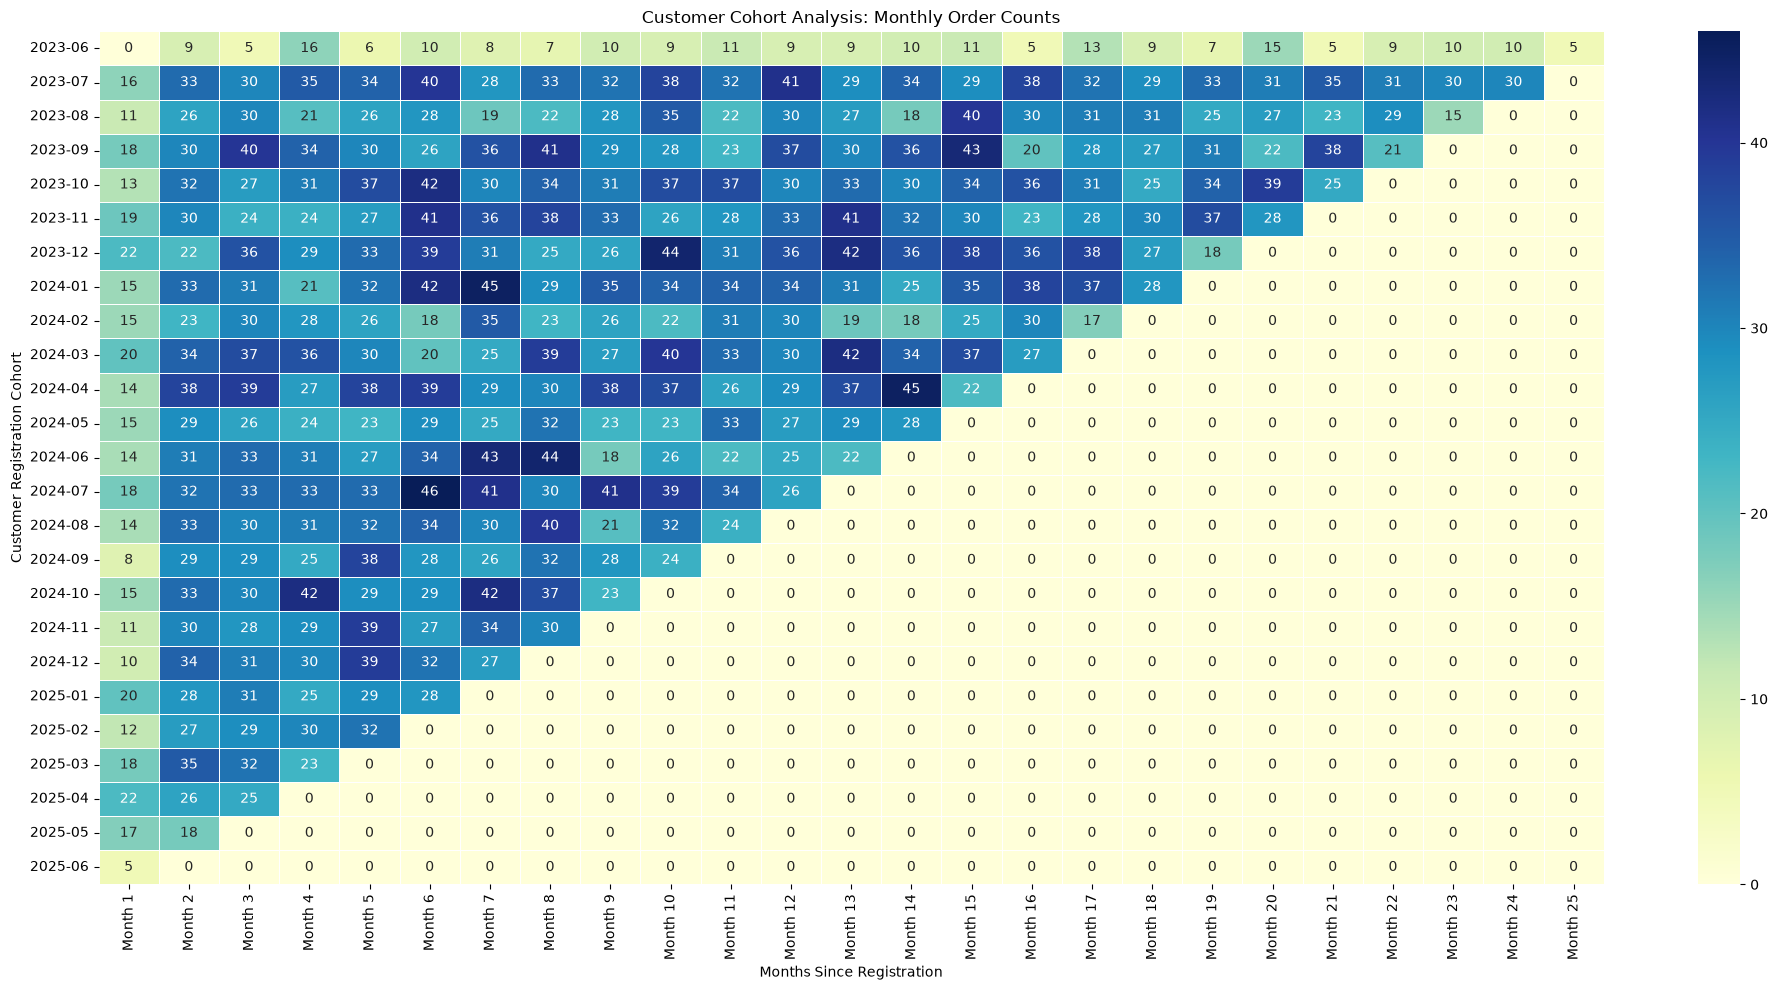

In [87]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(20, 10))

sns.heatmap(
    cohort_active_customers,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5,
    mask=cohort_active_customers.isna()
)

plt.title("Customer Cohort Analysis: Monthly Order Counts")
plt.xlabel("Months Since Registration")
plt.ylabel("Customer Registration Cohort")
plt.tight_layout()
plt.savefig("../outputs/charts/chart_11_customer_cohort_order_counts.png",
            dpi=300, bbox_inches="tight")
plt.show()

### Key Findings (Order-count heatmap)

1. **Monthly order activity:** The cohort heatmap shows how order volumes vary across registration cohorts and the months following registration.

2. **Variation across cohorts:** Some cohorts record higher monthly order counts than others, indicating differences in observed purchasing activity.

3. **Different observation periods:** Older cohorts have more months of order history available, while recent cohorts have fewer observed months. Comparisons should account for this difference.

4. **Data-quality limitation:** The customer registration data begins on 24 June 2020, while the order data begins on 24 June 2023. Therefore, earlier cohorts lack complete historical order coverage.

5. **Excluded records:** A total of 9,875 orders occurred before the recorded registration month and were excluded from this cohort analysis. The original data was not modified.

6. **Interpretation caution:** The heatmap displays order counts, not unique customers retained. It should not be interpreted as a customer-retention rate.

This is the order-count heatmap, now, lets create a true customer-retention heatmap.

The important difference is:
- Order-count heatmap: Counts how many orders a cohort places each month.
- Customer-retention heatmap: Measures what percentage of customers in a cohort place at least one order in each subsequent month.

For example, suppose 100 customers registered in July 2023. If 40 of those customers placed at least one order in August, the Month 2 retention rate would be 40% — regardless of whether those customers placed 40 orders or 70 orders in total.

The datasets already have the necessary columns:
- customers: customer_id, registration_date
- orders: customer_id, order_date

We can combine them to identify each customer's registration cohort and count unique customers who placed at least one order in each cohort month.

Although, there is one limitation: orders begin on June 24, 2023, but registrations begin on June 24, 2020. Earlier cohorts have incomplete order history, so we should focus on cohorts whose registration dates fall within the available order-history period and clearly document that limitation.

##### So now, we'll create a separate analysis so your original order-count heatmap remains intact.

In [62]:
retention_data = orders.merge(
    customers[["customer_id", "registration_date"]],
    on="customer_id",
    how="inner"
)

retention_data["registration_date"] = pd.to_datetime(
    retention_data["registration_date"]
)
retention_data["order_date"] = pd.to_datetime(
    retention_data["order_date"]
)

retention_data = retention_data[
    (retention_data["registration_date"] >= "2023-06-24")
    & (retention_data["order_date"] >= retention_data["registration_date"])
].copy()

retention_data["cohort_month"] = (
    retention_data["registration_date"].dt.to_period("M")
)

retention_data["order_month"] = (
    retention_data["order_date"].dt.to_period("M")
)

retention_data["cohort_age"] = (
    (retention_data["order_month"].dt.year - retention_data["cohort_month"].dt.year) * 12
    + (retention_data["order_month"].dt.month - retention_data["cohort_month"].dt.month)
    + 1
)

print("Valid customer-order records:", len(retention_data))
print("Unique customers with qualifying orders:", retention_data["customer_id"].nunique())

Valid customer-order records: 10235
Unique customers with qualifying orders: 3085


We have 10,235 qualifying order records from 3,085 unique customers.

Let's count unique active customers per cohort month


In [65]:
customer_activity = retention_data.drop_duplicates(
    subset=["customer_id", "cohort_month", "cohort_age"]
)

cohort_active_customers = customer_activity.pivot_table(
    index="cohort_month",
    columns="cohort_age",
    values="customer_id",
    aggfunc="nunique",
    fill_value=0
)

cohort_active_customers.columns = [
    f"Month {month}" for month in cohort_active_customers.columns
]

cohort_active_customers.head(20)

,Month 1,Month 2,Month 3,Month 4,Month 5,Month 6,Month 7,Month 8,Month 9,Month 10,...,Month 16,Month 17,Month 18,Month 19,Month 20,Month 21,Month 22,Month 23,Month 24,Month 25
cohort_month,,,,,,,,,,,,,,,,,,,,,
2023-06,0,9,5,16,6,10,8,7,10,9,...,5,13,9,7,15,5,9,10,10,5
2023-07,16,33,30,35,34,40,28,33,32,38,...,38,32,29,33,31,35,31,30,30,0
2023-08,11,26,30,21,26,28,19,22,28,35,...,30,31,31,25,27,23,29,15,0,0
2023-09,18,30,40,34,30,26,36,41,29,28,...,20,28,27,31,22,38,21,0,0,0
2023-10,13,32,27,31,37,42,30,34,31,37,...,36,31,25,34,39,25,0,0,0,0
2023-11,19,30,24,24,27,41,36,38,33,26,...,23,28,30,37,28,0,0,0,0,0
2023-12,22,22,36,29,33,39,31,25,26,44,...,36,38,27,18,0,0,0,0,0,0
2024-01,15,33,31,21,32,42,45,29,35,34,...,38,37,28,0,0,0,0,0,0,0
2024-02,15,23,30,28,26,18,35,23,26,22,...,30,17,0,0,0,0,0,0,0,0


We can now see how many unique customers in each registration cohort placed orders in each subsequent month.

Also, the June 2023 cohort has 0 customers in Month 1 but 9 in Month 2. This is because the available order history starts on June 24, 2023, so we don't have complete Month 1 order activity for that cohort.

NEXT: we'll calculate true customer retention rates

In [68]:
cohort_sizes = cohort_active_customers["Month 1"]

cohort_retention = cohort_active_customers.div(
    cohort_sizes.replace(0, pd.NA),
    axis=0
) * 100

cohort_retention = cohort_retention.round(2)

cohort_retention.head(20)

,Month 1,Month 2,Month 3,Month 4,Month 5,Month 6,Month 7,Month 8,Month 9,Month 10,...,Month 16,Month 17,Month 18,Month 19,Month 20,Month 21,Month 22,Month 23,Month 24,Month 25
cohort_month,,,,,,,,,,,,,,,,,,,,,
2023-06,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2023-07,100.0,206.25,187.5,218.75,212.5,250.0,175.0,206.25,200.0,237.5,...,237.5,200.0,181.25,206.25,193.75,218.75,193.75,187.5,187.5,0.0
2023-08,100.0,236.363636,272.727273,190.909091,236.363636,254.545455,172.727273,200.0,254.545455,318.181818,...,272.727273,281.818182,281.818182,227.272727,245.454545,209.090909,263.636364,136.363636,0.0,0.0
2023-09,100.0,166.666667,222.222222,188.888889,166.666667,144.444444,200.0,227.777778,161.111111,155.555556,...,111.111111,155.555556,150.0,172.222222,122.222222,211.111111,116.666667,0.0,0.0,0.0
2023-10,100.0,246.153846,207.692308,238.461538,284.615385,323.076923,230.769231,261.538462,238.461538,284.615385,...,276.923077,238.461538,192.307692,261.538462,300.0,192.307692,0.0,0.0,0.0,0.0
2023-11,100.0,157.894737,126.315789,126.315789,142.105263,215.789474,189.473684,200.0,173.684211,136.842105,...,121.052632,147.368421,157.894737,194.736842,147.368421,0.0,0.0,0.0,0.0,0.0
2023-12,100.0,100.0,163.636364,131.818182,150.0,177.272727,140.909091,113.636364,118.181818,200.0,...,163.636364,172.727273,122.727273,81.818182,0.0,0.0,0.0,0.0,0.0,0.0
2024-01,100.0,220.0,206.666667,140.0,213.333333,280.0,300.0,193.333333,233.333333,226.666667,...,253.333333,246.666667,186.666667,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2024-02,100.0,153.333333,200.0,186.666667,173.333333,120.0,233.333333,153.333333,173.333333,146.666667,...,200.0,113.333333,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


The calculated percentages exceed 100%, reaching values such as 362.5% and 475%.

That happens because our denominator is the number of customers who ordered in Month 1, while the numerator includes customers who ordered in a later month. Since the numerator can include different customers, this calculation is not true customer retention.

A proper retention rate is the percentage of the original cohort who also ordered in a later month. We need to count customers who ordered in both Month 1 and the later month.

In [75]:
cohort_sizes = cohort_active_customers["Month 1"]

first_month_customers = customer_activity[
    customer_activity["cohort_age"] == 1
][["customer_id", "cohort_month"]].drop_duplicates()

active_customers_by_month = customer_activity[
    ["customer_id", "cohort_month", "cohort_age"]
].drop_duplicates()

retained_customers = active_customers_by_month.merge(
    first_month_customers,
    on=["customer_id", "cohort_month"],
    how="inner"
)

retained_counts = retained_customers.pivot_table(
    index="cohort_month",
    columns="cohort_age",
    values="customer_id",
    aggfunc="nunique",
    fill_value=0
)

retained_counts.columns = [
    f"Month {month}" for month in retained_counts.columns
]

cohort_sizes = first_month_customers.groupby(
    "cohort_month"
)["customer_id"].nunique()

cohort_retention = retained_counts.div(
    cohort_sizes.replace(0, pd.NA),
    axis=0
).mul(100).round(2)

cohort_retention.head(10)

cohort_retention = cohort_retention.round(2)

cohort_retention.head(20)

,Month 1,Month 2,Month 3,Month 4,Month 5,Month 6,Month 7,Month 8,Month 9,Month 10,...,Month 15,Month 16,Month 17,Month 18,Month 19,Month 20,Month 21,Month 22,Month 23,Month 24
cohort_month,,,,,,,,,,,,,,,,,,,,,
2023-07,100.0,37.50,25.00,25.00,25.00,31.25,12.50,31.25,6.25,37.50,...,18.75,12.50,18.75,18.75,12.50,25.00,18.75,37.50,25.00,6.25
2023-08,100.0,9.09,27.27,27.27,27.27,18.18,27.27,18.18,45.45,63.64,...,45.45,18.18,9.09,18.18,27.27,18.18,9.09,9.09,18.18,0.00
2023-09,100.0,22.22,44.44,16.67,16.67,16.67,16.67,16.67,38.89,38.89,...,33.33,11.11,0.00,11.11,16.67,11.11,22.22,11.11,0.00,0.00
2023-10,100.0,15.38,23.08,15.38,0.00,7.69,7.69,15.38,15.38,23.08,...,23.08,15.38,23.08,15.38,7.69,15.38,23.08,0.00,0.00,0.00
2023-11,100.0,36.84,5.26,15.79,31.58,21.05,10.53,31.58,10.53,26.32,...,26.32,10.53,10.53,26.32,42.11,10.53,0.00,0.00,0.00,0.00
2023-12,100.0,22.73,22.73,13.64,40.91,31.82,22.73,9.09,13.64,36.36,...,31.82,18.18,13.64,22.73,18.18,0.00,0.00,0.00,0.00,0.00
2024-01,100.0,20.00,20.00,6.67,6.67,26.67,46.67,33.33,26.67,26.67,...,33.33,13.33,20.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2024-02,100.0,13.33,20.00,13.33,40.00,13.33,40.00,40.00,26.67,6.67,...,13.33,20.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2024-03,100.0,25.00,30.00,20.00,15.00,20.00,20.00,20.00,20.00,15.00,...,30.00,20.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


- Month 1 = 100% for each cohort with qualifying customers, because it is the baseline.



- Month 2, Month 3, etc. represent the percentage of that cohort's customers who placed at least one order in each subsequent month.



- For example, the July 2023 cohort shows 37.50% in Month 2 and 25.00% in Month 3.

In [81]:
print("Retention table shape:", cohort_retention.shape)
print("Columns:", cohort_retention.columns.tolist())
print("Last cohort:", cohort_retention.index[-1])
print(cohort_retention.tail(3).iloc[:, :8])

Retention table shape: (24, 24)
Columns: ['Month 1', 'Month 2', 'Month 3', 'Month 4', 'Month 5', 'Month 6', 'Month 7', 'Month 8', 'Month 9', 'Month 10', 'Month 11', 'Month 12', 'Month 13', 'Month 14', 'Month 15', 'Month 16', 'Month 17', 'Month 18', 'Month 19', 'Month 20', 'Month 21', 'Month 22', 'Month 23', 'Month 24']
Last cohort: 2025-06
              Month 1  Month 2  Month 3  Month 4  Month 5  Month 6  Month 7  \
cohort_month                                                                  
2025-04         100.0    18.18    27.27      0.0      0.0      0.0      0.0   
2025-05         100.0     5.88     0.00      0.0      0.0      0.0      0.0   
2025-06         100.0     0.00     0.00      0.0      0.0      0.0      0.0   

              Month 8  
cohort_month           
2025-04           0.0  
2025-05           0.0  
2025-06           0.0  


The future months with no available data aren't misleadingly displayed as zero retention. A cohort that hasn't reached Month 20 yet should have missing values for those future months, not zeros.

The latest cohorts have future months incorrectly represented as 0% retention. For example, the June 2025 cohort cannot yet have 8 months of observed activity when the dataset ends on June 23, 2025.

In [82]:
cohort_retention_corrected = cohort_retention.copy()

latest_order_month = orders["order_date"].max().to_period("M")

for i, cohort in enumerate(cohort_retention_corrected.index):
    observed_months = (
        (latest_order_month.year - cohort.year) * 12
        + latest_order_month.month - cohort.month + 1
    )
    cohort_retention_corrected.iloc[i, observed_months:] = float("nan")

cohort_retention_corrected.tail(3).iloc[:, :8]

,Month 1,Month 2,Month 3,Month 4,Month 5,Month 6,Month 7,Month 8
cohort_month,,,,,,,,
2025-04,100.0,18.18,27.27,NaN,NaN,NaN,NaN,NaN
2025-05,100.0,5.88,NaN,NaN,NaN,NaN,NaN,NaN
2025-06,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Now the future, unobserved months are represented by NaN rather than misleading 0% retention.

For example:
- April 2025: Month 1–3 have observed values; Month 4 onward is unavailable.
- May 2025: Month 1–2 have observed values; Month 3 onward is unavailable.
- June 2025: Only Month 1 is observed.

This is important because 0% means no customers returned, whereas NaN means the period hasn't been observed yet.

#### now lets generate the heatmap

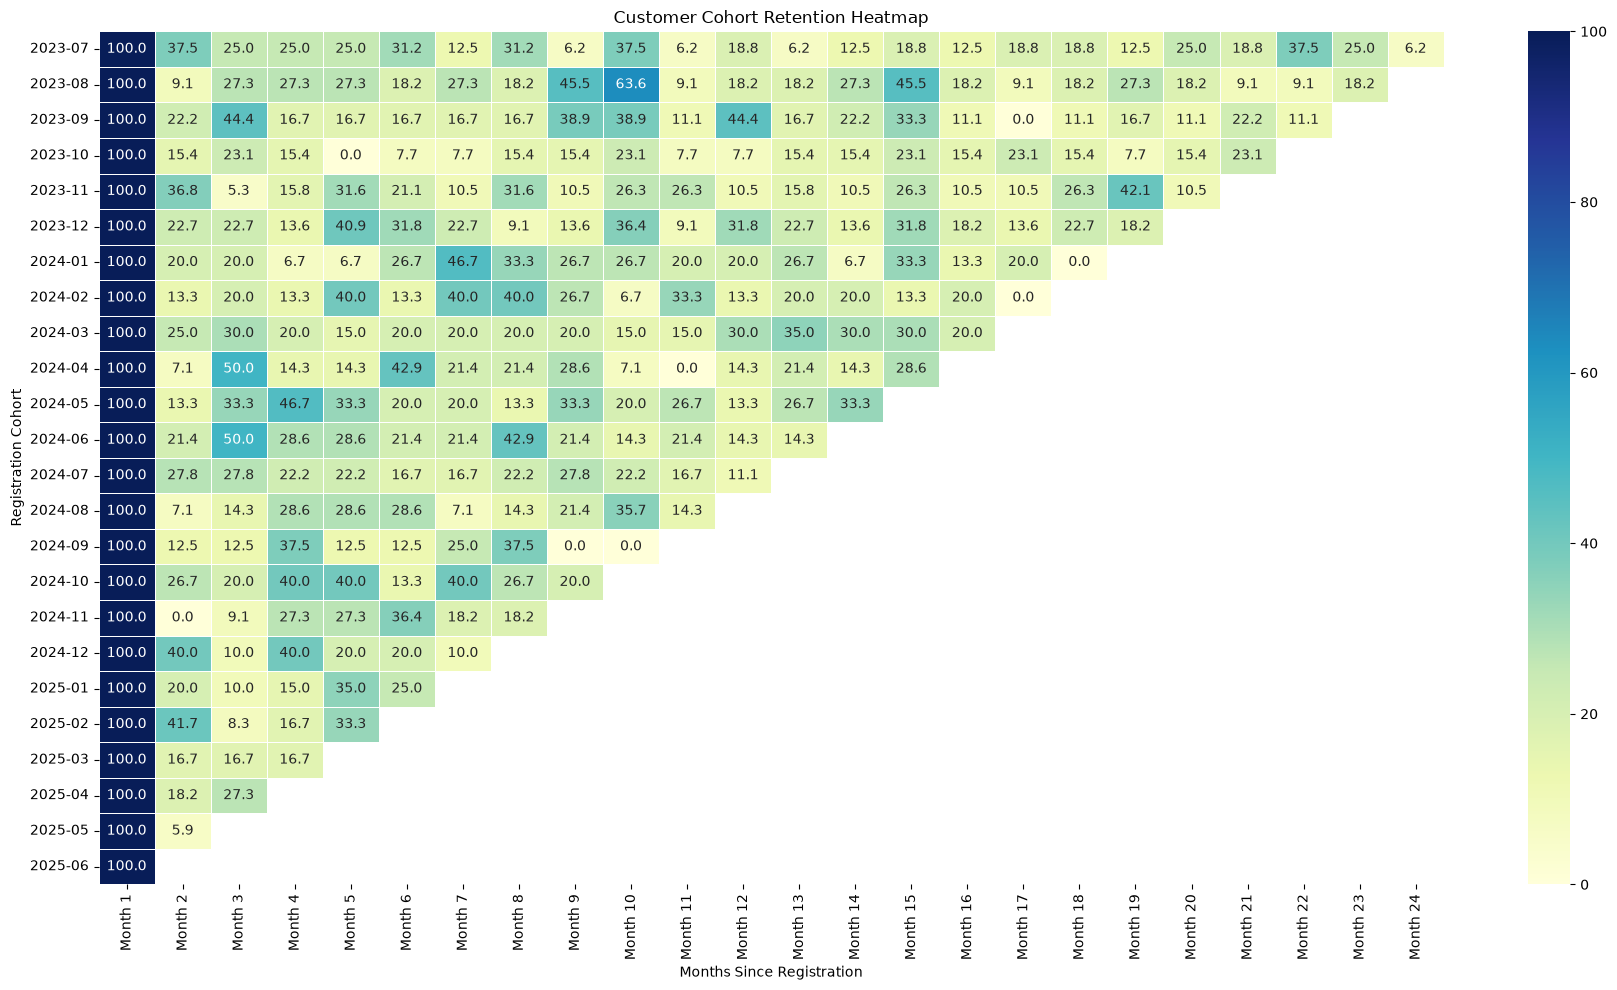

In [84]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(18, 10))

sns.heatmap(
    cohort_retention_corrected,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    mask=cohort_retention_corrected.isna()
)

plt.title("Customer Cohort Retention Heatmap")
plt.xlabel("Months Since Registration")
plt.ylabel("Registration Cohort")
plt.tight_layout()

plt.savefig(
    "../outputs/charts/chart_12_customer_cohort_retention.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

- July 2023 cohort: Retention falls from 100% in Month 1 to 37.5% in Month 2 and 25% in Month 3.



- April 2024 cohort: Month 3 retention reaches 50%, indicating that half of the cohort's Month 1 customers placed an order in Month 3.



- Retention varies across cohorts: Some cohorts show stronger repeat purchasing in later months than others. This suggests retention isn't declining uniformly.



- Recent cohorts have less history: The May and June 2025 cohorts have very few observed months, so we shouldn't compare their long-term retention with older cohorts yet.

### Analysis: Customer Cohort Retention HeatMap

Cohort analysis groups customers by their registration month and tracks their repeat purchasing behaviour over time. The retention heatmap shows the percentage of customers from each cohort who placed at least one order in each subsequent month.

**Key Insights:**
1. The July 2023 cohort retained 37.5% of its Month 1 customers in Month 2 and 25% in Month 3.
2. Retention varies between registration cohorts, indicating differences in repeat-purchase behaviour.
3. Some cohorts experience stronger retention in particular months, so retention does not decline uniformly.
4. Recent cohorts have fewer observed months and should not be compared directly with older cohorts for long-term retention.
5. These results can help IndiaKart identify customer groups that may benefit from targeted retention campaigns, loyalty offers, and repeat-purchase incentives.
6. Month 1 is set to 100% by definition because it represents the baseline cohort.

**Methodology and Limitation:** Retention is calculated using unique customers who placed at least one order in each cohort month, divided by the cohort's Month 1 customer count. Orders dated before customer registration were excluded. Months beyond the available observation period are displayed as blank rather than 0%. The results describe observed purchasing behaviour and do not establish the causes of customer retention.